# FarmRL: reinforcement learning for crop input management

**Team:** Harshita Vachhani (B23EE1026), Aurindum Banerjee (B23CS1006) · AI Assignment 2

This notebook is the end-to-end record of the project: data, yield model, environment,
training and evaluation. All logic lives in `src/farmrl/`; the notebook only calls it and
plots. Every figure is also saved to `results/figures/` at 300 dpi for the report.

## 1. Introduction and RL formulation

A wheat farmer in Punjab decides, fortnight by fortnight, how much nitrogen to apply,
whether to irrigate and whether to spray, without knowing the rest of the season's weather.
Too little input loses yield; too much wastes money, leaches nitrate, draws down groundwater
and (for water) directly hurts the crop. We model one season as an episodic Markov decision
process and train an agent to maximise net profit per hectare.

**Episode.** One wheat season at Ludhiana, sown on 1 November, in $T = 12$ fortnightly steps.
Each episode replays the weather of one real season.

**State** (11 numbers, all observed by the agent):

$$
s_t = \big(\,t/T,\; \theta_t,\; N^{soil}_t,\; p_t,\; \textstyle\sum_{k<t} R_k,\; \sum_{k<t} n_k,\; \sum_{k<t}(R_k + w_k),\; P/P_0,\; R_{t-1},\; ET_{0,t-1},\; \rho_t \big)
$$

with $\theta$ soil moisture (fraction of capacity), $N^{soil}$ soil mineral nitrogen, $p$ pest
pressure, $R$ rainfall, $P$ the season's wheat price, and
$\rho_t = \sum ET_a / \sum ET_c$ the share of crop water demand met so far.

**Action.** $a_t = (n_t, w_t, q_t)$, a `MultiDiscrete([3, 3, 3])` choice of

$$
n_t \in \{0, 20, 40\}\ \text{kg N/ha}, \qquad w_t \in \{0, 37.5, 75\}\ \text{mm}, \qquad q_t \in \{0, 1, 2\}\ \text{(pesticide dose)}.
$$

**Transition.** A soil water bucket driven by real rain and reference evapotranspiration,
a soil nitrogen pool, and a stochastic pest population:

$$
\theta_{t+1} = \frac{\min\{C,\; \theta_t C + R_t + w_t - D_t\} - ET_{a,t}}{C}, \qquad
N^{soil}_{t+1} = \gamma_N (1 - \ell_t) N^{soil}_t + n_t, \qquad
p_{t+1} = \mathrm{clip}\big(p_t\, g_t\, (1 - \kappa q_t),\, 0,\, 1\big)
$$

where $D_t$ is drainage, $\ell_t$ the leached share and $g_t = 1 + U(0.1, 0.6)\cdot RH_t/\overline{RH}$.

**Reward.** Input costs and environmental penalties are paid every step, the crop is sold at harvest:

$$
r_t = -\frac{1}{\kappa_r}\Big[\underbrace{c_N n_t + c_W w_t + c_P q_t}_{\text{input cost}}
 + \underbrace{\lambda_N \max(0, N^{soil}_{t+1} - 80) + \lambda_P q_t + \lambda_W w_t}_{\text{environmental penalty}}\Big]
 + \frac{\mathbb{1}[t = T-1]}{\kappa_r}\,\big(Y \cdot P - F\big)
$$

$$
Y = y_{max}\,\big[1 - e^{-\beta_N (N_{eff} + N_0)}\big]\,\Big[1 - \beta_W \max\big(0, \tfrac{W - W^*}{100}\big)^2\Big]\,\big[1 - K_y (1 - \rho_T)\big]\,\big[1 - L\, D_{pest}\big]
$$

$F$ is the fixed cost of the season (labour, machinery, seed, ...), $\kappa_r = 10^4$ only rescales
the reward. The objective is $\max_\pi \mathbb{E}\big[\sum_{t=0}^{T-1} \gamma^t r_t\big]$ with $\gamma = 0.99$.
We report **net profit** $Y P - F - \sum_t(\text{input cost})$ in INR/ha, i.e. the reward without
the penalty terms.

**Algorithm.** Proximal Policy Optimisation with a clipped surrogate objective and GAE,
implemented from scratch in `src/farmrl/agents/ppo.py`.

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from farmrl import data_loader as dl
from farmrl.yield_model import YieldModel, PRIORS
from farmrl.env import FarmEnv, OBS_NAMES, calibrate_yield_scale
from farmrl.baselines import BASELINES, recommended_schedule
from farmrl.evaluation import evaluate, summarise, run_episode
from farmrl.agents.ppo import PPO
from farmrl.utils import load_config, set_seed, save_fig, set_plot_style, COLORS, POLICY_COLORS

cfg = load_config(ROOT / "configs/default.yaml")
SEED = cfg["env"]["seed"]
set_seed(SEED)
set_plot_style()
pd.set_option("display.precision", 2)
MUTED = "#898781"

def show(fig, name):
    path = save_fig(fig, name)
    plt.show()
    print("saved", path.relative_to(ROOT))

## 2. Data loading and exploratory analysis

`scripts/download_data.py` fetches the raw files and `farmrl.data_loader` cleans them into
`data/processed/`. Nothing below is synthetic: a dataset that could not be obtained is
reported as missing and the corresponding plot is skipped.

| Dataset | Used for | Status |
|---|---|---|
| NASA POWER daily weather, Ludhiana, 1985–2024 | environment weather | downloaded |
| NASA POWER daily weather, 7 Haryana district HQs | season rain for the yield fit | downloaded |
| ICRISAT district-level data (crops, fertiliser) | yield response fit | supplied manually: **Haryana**, 7 districts, 2008–2017 |
| RBI Handbook, wheat MSP by crop year | price series | downloaded |
| CACP Rabi price policy report 2027-28 | per-hectare costs (Punjab, 2024-25) | downloaded, table transcribed |
| FAO yield + pesticides (Kaggle `yield_df.csv`) | pesticide response | needs `~/.kaggle/kaggle.json` |
| Agmarknet mandi prices | market price series | needs data.gov.in key / manual export |

The cell below reports what is actually on disk.

In [2]:
daily = dl.load_weather(cfg["env"]["weather_site"])
seasons = dl.load_seasons(cfg["env"]["weather_site"], steps=cfg["env"]["steps_per_season"])
summary = dl.season_summary(seasons)
train_years, test_years = dl.split_seasons(seasons, cfg["env"]["train_end"])
icrisat = dl.load_icrisat("wheat")
fit_table = dl.build_fit_table("wheat")
prices = dl.load_prices()
costs = dl.load_cost_of_cultivation()

def optional(loader):
    try:
        return loader()
    except FileNotFoundError as err:
        print("MISSING:", err)

fao = optional(dl.load_fao_pesticides)
mandi = optional(dl.load_agmarknet)

print(f"weather   : {len(daily)} days, {daily['date'].min():%Y-%m-%d} to {daily['date'].max():%Y-%m-%d}; "
      f"{summary['season'].nunique()} complete seasons")
print(f"ICRISAT   : {len(icrisat)} district-years, states {sorted(icrisat['state'].unique())}, "
      f"{icrisat['district'].nunique()} districts, {icrisat['year'].min()}-{icrisat['year'].max()}")
print(f"prices    : {len(prices)} seasons {prices['season'].min()}-{prices['season'].max()}, "
      f"sources {sorted(prices['source'].unique())}")
print(f"costs     : CACP years {sorted(costs['year'].unique())}")
print(f"FAO       : {'%d years' % len(fao) if fao is not None else 'not available'}")
print(f"Agmarknet : {'%d months' % len(mandi) if mandi is not None else 'not available'}")

MISSING: D:\MyStuff\College\.7thSemester\AI\Ass2\FarmRL\data\raw\yield_df.csv not found -- run scripts/download_data.py kaggle (needs ~/.kaggle/kaggle.json)
MISSING: D:\MyStuff\College\.7thSemester\AI\Ass2\FarmRL\data\raw\agmarknet_wheat_punjab.csv not found -- see scripts/download_data.py prices
weather   : 14610 days, 1985-01-01 to 2024-12-31; 39 complete seasons
ICRISAT   : 70 district-years, states ['Haryana'], 7 districts, 2008-2017
prices    : 45 seasons 1981-2025, sources ['MSP (RBI Handbook)']
costs     : CACP years ['2022-23', '2023-24', '2024-25']
FAO       : not available
Agmarknet : not available


### 2.1 Rainfall

Wheat is a winter (rabi) crop: the season is dry, with on average about 110 mm of rain
between November and April, most of it from western disturbances in January–March. The
spread between years is large, which is what makes a fixed irrigation calendar wasteful.

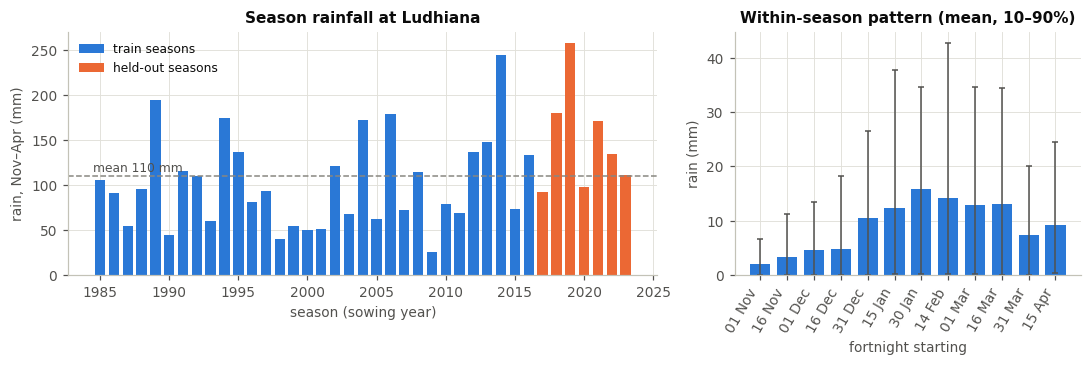

saved results\figures\eda_rainfall.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1.7, 1]})
ax = axes[0]
is_test = summary["season"] > cfg["env"]["train_end"]
ax.bar(summary["season"][~is_test], summary["rain_mm"][~is_test], color=COLORS[0], width=0.75, label="train seasons")
ax.bar(summary["season"][is_test], summary["rain_mm"][is_test], color=COLORS[1], width=0.75, label="held-out seasons")
ax.axhline(summary["rain_mm"].mean(), color=MUTED, lw=1, ls="--")
ax.text(summary["season"].min() - 0.5, summary["rain_mm"].mean() + 5, f"mean {summary['rain_mm'].mean():.0f} mm", color="#52514e", fontsize=8)
ax.set(xlabel="season (sowing year)", ylabel="rain, Nov–Apr (mm)", title="Season rainfall at Ludhiana")
ax.legend(loc="upper left")

ax = axes[1]
by_step = seasons.groupby("step")["rain_mm"]
labels = seasons[seasons["season"] == seasons["season"].min()]["start_date"].map(lambda d: pd.Timestamp(d).strftime("%d %b"))
ax.bar(range(len(labels)), by_step.mean(), color=COLORS[0], width=0.75)
ax.errorbar(range(len(labels)), by_step.mean(), yerr=[by_step.mean() - by_step.quantile(0.1), by_step.quantile(0.9) - by_step.mean()],
            fmt="none", ecolor="#52514e", elinewidth=1, capsize=2)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=60, ha="right")
ax.set(xlabel="fortnight starting", ylabel="rain (mm)", title="Within-season pattern (mean, 10–90%)")
fig.tight_layout()
show(fig, "eda_rainfall")

### 2.2 Temperature and evaporative demand

Temperature falls to a minimum in January and climbs steeply from March; the last fortnights
are hot and dry, so crop water demand ($ET_c = K_c \cdot ET_0$) peaks during grain filling.
Reference evapotranspiration $ET_0$ is computed from temperature and solar radiation
(Hargreaves radiation form) in `data_loader.load_weather`.

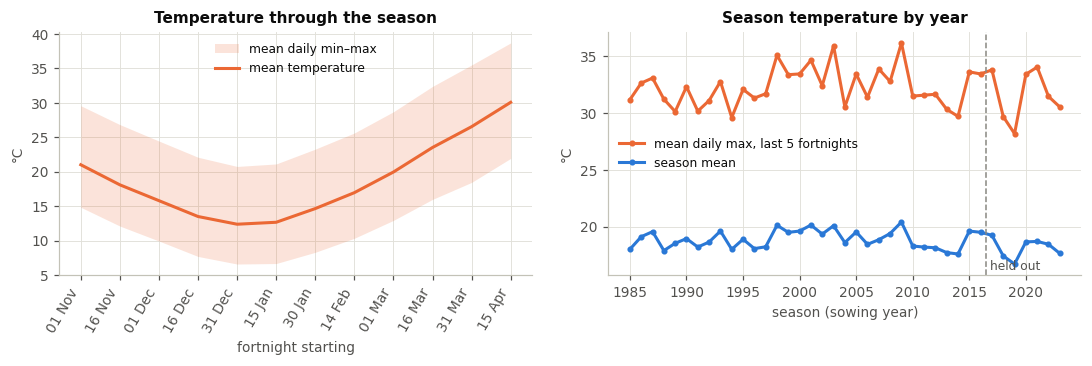

saved results\figures\eda_temperature.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
g = seasons.groupby("step")
fx = range(len(labels))
ax.fill_between(fx, g["t_min"].mean(), g["t_max"].mean(), color=COLORS[1], alpha=0.18, lw=0, label="mean daily min–max")
ax.plot(fx, g["t_mean"].mean(), color=COLORS[1], label="mean temperature")
ax.set_xticks(fx); ax.set_xticklabels(labels, rotation=60, ha="right")
ax.set(xlabel="fortnight starting", ylabel="°C", title="Temperature through the season")
ax.legend(loc="upper center")

ax = axes[1]
ax.plot(summary["season"], summary["late_t_max"], color=COLORS[1], marker="o", ms=3, label="mean daily max, last 5 fortnights")
ax.plot(summary["season"], summary["t_mean"], color=COLORS[0], marker="o", ms=3, label="season mean")
ax.axvline(cfg["env"]["train_end"] + 0.5, color=MUTED, lw=1, ls="--")
ax.text(cfg["env"]["train_end"] + 0.8, ax.get_ylim()[0] + 0.5, "held out", color="#52514e", fontsize=8)
ax.set(xlabel="season (sowing year)", ylabel="°C", title="Season temperature by year")
ax.legend(loc="center left")
fig.tight_layout()
show(fig, "eda_temperature")

### 2.3 Yield trends

The ICRISAT files we have cover seven (1966-boundary) districts of **Haryana** for
2008–2017, not Punjab. Haryana is the neighbouring state in the same irrigated
rice–wheat belt, so we use it to fit the response curve, and flag it as a limitation.
Yields move together across districts: 2014 (harvest 2015, heavy March rain) is low
everywhere and 2011 is high everywhere, so most of the variance is a common weather signal.

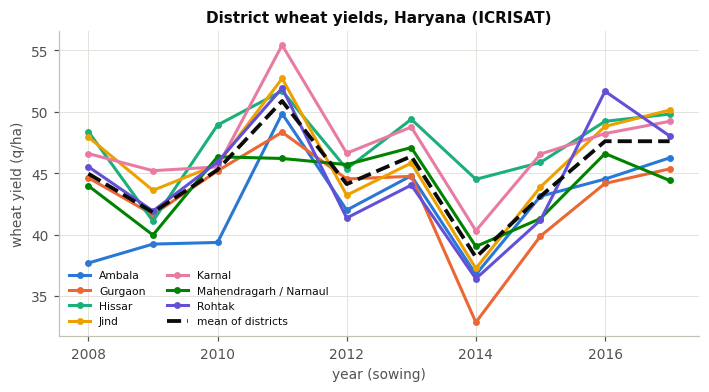

saved results\figures\eda_yield_trends.png


In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for color, (district, g) in zip(COLORS, icrisat.groupby("district")):
    ax.plot(g["year"], g["yield_q_ha"], marker="o", ms=3.5, color=color, label=district)
ax.plot(icrisat.groupby("year")["yield_q_ha"].mean(), color="#0b0b0b", lw=2.5, ls="--", label="mean of districts")
ax.set(xlabel="year (sowing)", ylabel="wheat yield (q/ha)", title="District wheat yields, Haryana (ICRISAT)")
ax.legend(ncol=2, loc="lower left", fontsize=7)
show(fig, "eda_yield_trends")

### 2.4 Fertiliser versus yield

Nitrogen use is district consumption per hectare of gross cropped area (all crops, whole
year), the closest proxy ICRISAT offers for the wheat dose. Every district-year already
applies at least 89 kg N/ha, so the data sit on the flat part of the response curve: the
raw correlation between nitrogen and yield is essentially zero. Season rainfall, by contrast,
is clearly *negatively* related to yield in this irrigated system.

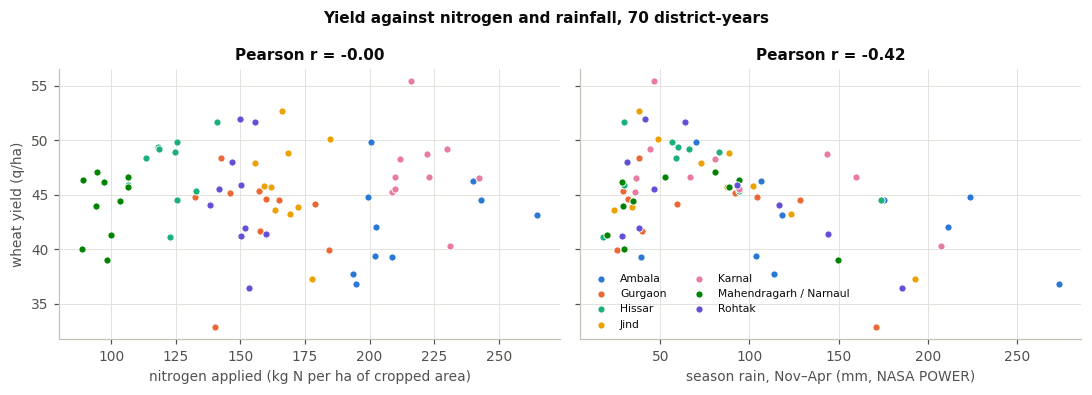

saved results\figures\eda_fertiliser_vs_yield.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, col, xlabel in [(axes[0], "n_kg_ha", "nitrogen applied (kg N per ha of cropped area)"),
                        (axes[1], "rain_mm", "season rain, Nov–Apr (mm, NASA POWER)")]:
    for color, (district, g) in zip(COLORS, fit_table.groupby("district")):
        ax.scatter(g[col], g["yield_q_ha"], s=22, color=color, edgecolor="white", lw=0.6, label=district)
    r = fit_table[[col, "yield_q_ha"]].corr().iloc[0, 1]
    ax.set(xlabel=xlabel, title=f"Pearson r = {r:+.2f}")
axes[0].set_ylabel("wheat yield (q/ha)")
axes[1].legend(fontsize=7, loc="lower left", ncol=2)
fig.suptitle("Yield against nitrogen and rainfall, 70 district-years", fontsize=10, fontweight="bold")
fig.tight_layout()
show(fig, "eda_fertiliser_vs_yield")

### 2.5 Pesticide versus yield

This plot needs the FAO table from Kaggle (`yield_df.csv`). It is drawn only if the file is
present; otherwise the cell says so and the pesticide-loss parameter stays at its prior.

In [7]:
if fao is None:
    print("yield_df.csv is not in data/raw, so there is no pesticide data to plot.")
    print("Add ~/.kaggle/kaggle.json, run `python scripts/download_data.py kaggle`, then re-run this notebook.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    axes[0].plot(fao["year"], fao["pesticides_t"] / 1000, color=COLORS[0], marker="o", ms=3)
    axes[0].set(xlabel="year", ylabel="pesticide use (kt)", title="India: pesticide use (FAO)")
    sc = axes[1].scatter(fao["pesticides_t"] / 1000, fao["yield_q_ha"], c=fao["year"], cmap="Blues", s=28, edgecolor="#52514e", lw=0.5)
    fig.colorbar(sc, ax=axes[1], label="year")
    r = fao[["pesticides_t", "yield_q_ha"]].corr().iloc[0, 1]
    axes[1].set(xlabel="pesticide use (kt)", ylabel="wheat yield (q/ha)", title=f"India wheat yield vs pesticide use (r = {r:+.2f})")
    fig.tight_layout()
    show(fig, "eda_pesticide_vs_yield")

yield_df.csv is not in data/raw, so there is no pesticide data to plot.
Add ~/.kaggle/kaggle.json, run `python scripts/download_data.py kaggle`, then re-run this notebook.


### 2.6 Prices and costs

No mandi series could be downloaded, so the price series is the wheat minimum support price
(MSP), which is what most Punjab wheat is actually sold at. Nominal MSP has grown sixteen-fold
since 1985, so old rupee values cannot sit next to today's costs. The environment therefore
uses a **price index**: each year's price relative to its own centred five-year trend,
multiplied by the 2024-25 MSP. The index stays mostly within ±5% of 1 (the largest deviation is about −12%, just before
the 2006 MSP jump), i.e. price risk for MSP wheat is small compared with weather risk.

Costs come from the CACP cost-of-cultivation table for Punjab wheat (2024-25).

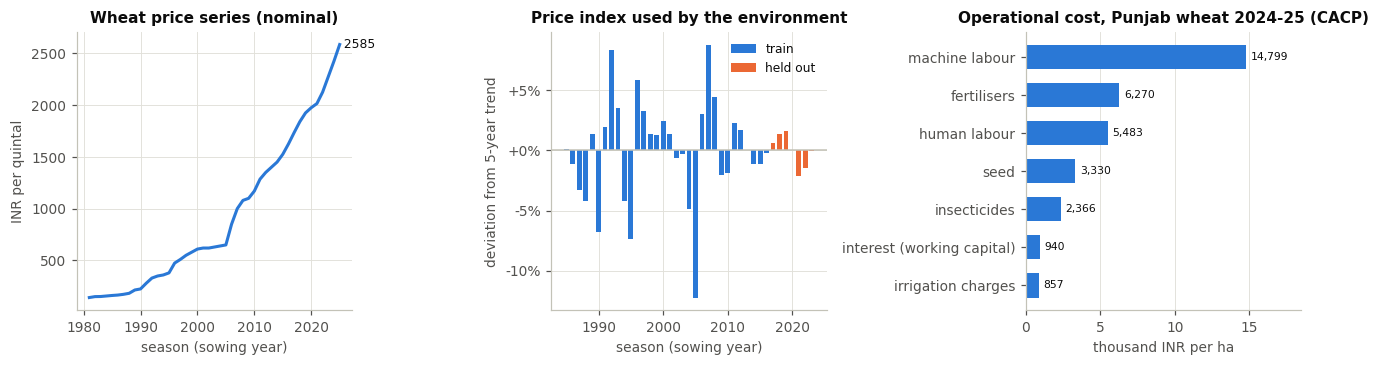

saved results\figures\eda_prices_costs.png
CACP 2024-25: operational cost 34,285 INR/ha, yield 53.0 q/ha


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
ax = axes[0]
ax.plot(prices["season"], prices["price"], color=COLORS[0])
ax.set(xlabel="season (sowing year)", ylabel="INR per quintal", title="Wheat price series (nominal)")
ax.text(prices["season"].iloc[-1], prices["price"].iloc[-1], f" {prices['price'].iloc[-1]:.0f}", va="center", fontsize=8)

ax = axes[1]
p = prices[prices["season"].between(summary["season"].min(), summary["season"].max())]
tr = p["season"] <= cfg["env"]["train_end"]
ax.bar(p["season"][tr], p["price_index"][tr] - 1, color=COLORS[0], width=0.75, label="train")
ax.bar(p["season"][~tr], p["price_index"][~tr] - 1, color=COLORS[1], width=0.75, label="held out")
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set(xlabel="season (sowing year)", ylabel="deviation from 5-year trend", title="Price index used by the environment")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.legend()

ax = axes[2]
latest = dl.latest_costs(costs)
year = costs["year"].max()
items = {"machine labour": latest["machine_labour_hired"] + latest["machine_labour_owned"],
         "fertilisers": latest["fertilisers"],
         "human labour": latest["human_labour_casual"] + latest["human_labour_attached"] + latest["human_labour_family"],
         "seed": latest["seed"], "insecticides": latest["insecticides"],
         "interest (working capital)": latest["interest_on_working_capital"],
         "irrigation charges": latest["irrigation_charges"]}
names = list(items)[::-1]
bars = ax.barh(names, [items[k] / 1000 for k in names], color=COLORS[0], height=0.65)
ax.bar_label(bars, labels=[f"{items[k]:,.0f}" for k in names], padding=3, fontsize=7)
ax.set(xlabel="thousand INR per ha", title=f"Operational cost, Punjab wheat {year} (CACP)")
ax.set_xlim(0, max(items.values()) / 1000 * 1.25); ax.grid(axis="y", visible=False)
fig.tight_layout()
show(fig, "eda_prices_costs")
print(f"CACP {year}: operational cost {latest['operational_cost']:,.0f} INR/ha, yield {latest['yield_q_per_ha']} q/ha")

## 3. Fitting the yield response model

`YieldModel.fit` estimates, with `scipy.optimize.curve_fit` (bounded least squares),

$$
Y = y_{max}\,\big[1 - e^{-\beta_N (N + N_0)}\big]\,\Big[1 - \beta_W \max\big(0, \tfrac{W - W^*}{100}\big)^2\Big]
$$

a Mitscherlich response to nitrogen times a quadratic penalty for water above an optimum
$W^*$. Two things about the data shape the fit:

* ICRISAT gives no irrigation depth, so every record is assigned the same assumed
  irrigation (300 mm, four standard irrigations): $W = \text{rain} + 300$. Only the sum
  $W^* - 300$ is really identified, i.e. *how much rain an irrigated crop tolerates*.
* The farms are irrigated and sprayed, so the records carry no information on drought or
  on unsprayed crops. The water-deficit term uses the FAO yield response factor
  $K_y = 1.15$ for wheat (literature constant) and the pest term is fitted only if the FAO
  pesticide table is available.

A parameter that ends on a bound or has a standard error larger than its estimate is
declared *not identified* and replaced by its prior, rather than silently kept.

In [9]:
model = YieldModel()
rep = model.fit(fit_table, assumed_irrigation=cfg["yield_fit"]["assumed_irrigation_mm"], pest_df=fao)

rows = []
for k in ["y_max", "n_coef", "w_opt", "w_excess"]:
    rows.append({"parameter": k, "value used": getattr(model, k), "std. error": rep["std_err"].get(k, np.nan),
                 "status": "fitted" if rep["identified"][k] else "not identified -> prior"})
pest = rep.get("pesticide")
rows.append({"parameter": "pest_loss", "value used": model.pest_loss,
             "std. error": pest["std_err"] if pest else np.nan,
             "status": ("fitted (FAO)" if pest and pest["identified"] else
                        "not identified -> prior" if pest else "prior (no pesticide data)")})
rows.append({"parameter": "ky", "value used": model.ky, "std. error": np.nan, "status": "literature (FAO-33)"})
display(pd.DataFrame(rows).set_index("parameter"))
print(f"n = {rep['n_obs']} district-years   R² = {rep['r2']:.3f}   RMSE = {rep['rmse']:.2f} q/ha "
      f"(observed mean {rep['mean_observed_yield']:.1f} q/ha)")
print(f"nitrogen range in the data: {rep['n_range_kg_ha'][0]:.0f}-{rep['n_range_kg_ha'][1]:.0f} kg/ha; "
      f"water range: {rep['water_range_mm'][0]:.0f}-{rep['water_range_mm'][1]:.0f} mm")

,value used,std. error,status
parameter,,,
y_max,46.76,1.04e+00,fitted
n_coef,0.03,6.85e-03,fitted
w_opt,332.13,5.66e+01,fitted
w_excess,0.04,2.60e-02,fitted
pest_loss,0.35,NaN,prior (no pesticide data)
ky,1.15,NaN,literature (FAO-33)


n = 70 district-years   R² = 0.237   RMSE = 3.66 q/ha (observed mean 45.0 q/ha)
nitrogen range in the data: 89-265 kg/ha; water range: 318-573 mm


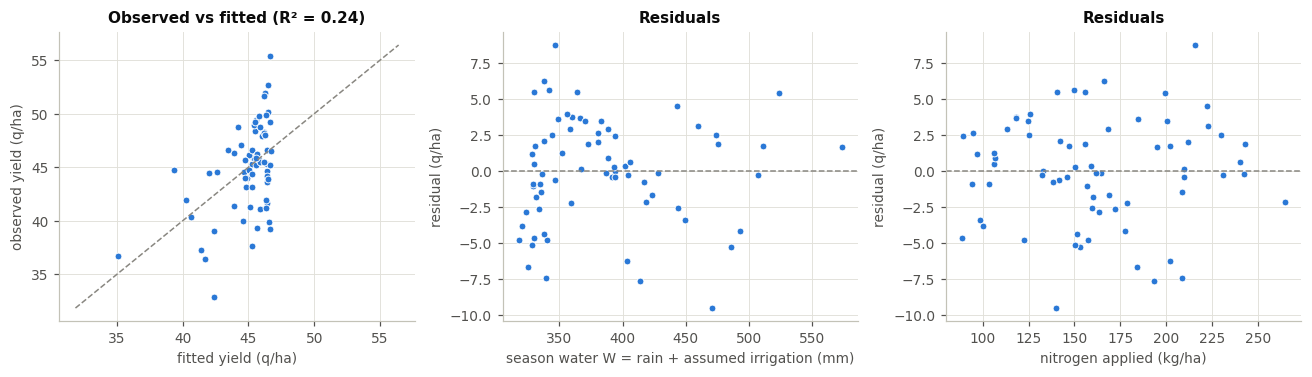

saved results\figures\yield_fit_diagnostics.png


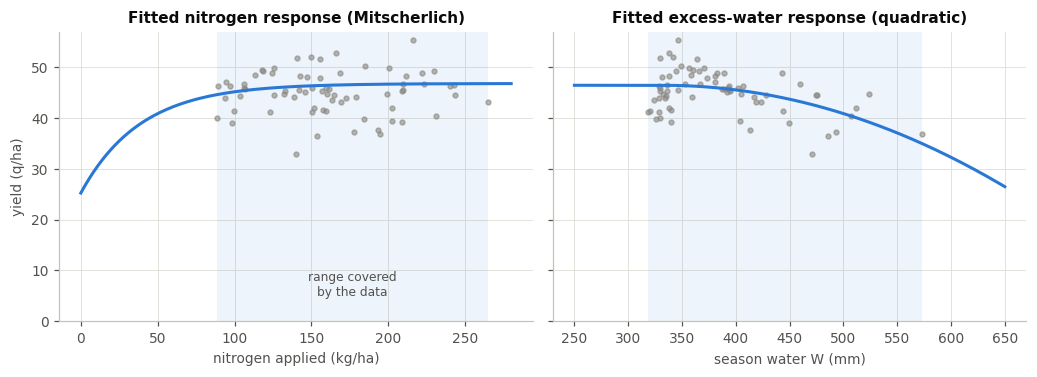

saved results\figures\yield_response_curves.png


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
obs, pred, res = rep["observed"], rep["predicted"], rep["residuals"]
ax = axes[0]
ax.scatter(pred, obs, s=20, color=COLORS[0], edgecolor="white", lw=0.6)
lim = [min(obs.min(), pred.min()) - 1, max(obs.max(), pred.max()) + 1]
ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
ax.set(xlabel="fitted yield (q/ha)", ylabel="observed yield (q/ha)", title=f"Observed vs fitted (R² = {rep['r2']:.2f})")

for ax, x, xlabel in [(axes[1], rep["water"], "season water W = rain + assumed irrigation (mm)"),
                      (axes[2], rep["n"], "nitrogen applied (kg/ha)")]:
    ax.scatter(x, res, s=20, color=COLORS[0], edgecolor="white", lw=0.6)
    ax.axhline(0, color=MUTED, lw=1, ls="--")
    ax.set(xlabel=xlabel, ylabel="residual (q/ha)", title="Residuals")
fig.tight_layout()
show(fig, "yield_fit_diagnostics")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.5), sharey=True)
n_grid = np.linspace(0, 280, 200)
axes[0].plot(n_grid, model.potential(n_grid, model.w_opt), color=COLORS[0])
axes[0].axvspan(*rep["n_range_kg_ha"], color=COLORS[0], alpha=0.08, lw=0)
axes[0].text(np.mean(rep["n_range_kg_ha"]), 5, "range covered\nby the data", ha="center", fontsize=8, color="#52514e")
axes[0].scatter(rep["n"], obs, s=10, color=MUTED, alpha=0.6)
axes[0].set(xlabel="nitrogen applied (kg/ha)", ylabel="yield (q/ha)", title="Fitted nitrogen response (Mitscherlich)", ylim=(0, None))
w_grid = np.linspace(250, 650, 200)
axes[1].plot(w_grid, model.potential(160, w_grid), color=COLORS[0])
axes[1].axvspan(*rep["water_range_mm"], color=COLORS[0], alpha=0.08, lw=0)
axes[1].scatter(rep["water"], obs, s=10, color=MUTED, alpha=0.6)
axes[1].set(xlabel="season water W (mm)", title="Fitted excess-water response (quadratic)")
fig.tight_layout()
show(fig, "yield_response_curves")

**Reading the fit honestly.** The model explains only about a quarter of the variance.
That is expected: with ten years of data the dominant signal is a shared year effect
(heat, hail, rust) that N and water totals cannot capture, and the residual plots show no
remaining structure against either input. What the data do support is (i) a plateau around
47 q/ha, (ii) a yield loss once season rain exceeds roughly 30 mm above normal irrigation,
and (iii) a nitrogen response that is already nearly saturated at observed doses. The curve
*below* 89 kg N/ha is an extrapolation of the Mitscherlich form, not something the data show.

### Calibrating the potential yield

The fitted plateau is the yield farmers actually obtained, after whatever water stress and
pest damage normal practice still leaves. The simulator applies those losses explicitly, so
its potential yield must sit above the plateau. `calibrate_yield_scale` chooses one scale
factor so that the standard recommended schedule, simulated over the training seasons,
reproduces the observed mean yield. The parameters are then saved for the environment.

In [11]:
scale = calibrate_yield_scale(cfg["env"], model, rep["mean_observed_yield"], recommended_schedule)
params_path = ROOT / cfg["env"]["fitted_params"]
states = "/".join(sorted(fit_table["state"].unique()))
model.save(params_path, source=f"ICRISAT district-level data ({states}, {fit_table['year'].min()}-{fit_table['year'].max()}) "
                               "+ NASA POWER season rainfall")
print(f"y_scale = {scale:.3f}  ->  potential yield {model.y_max * scale:.1f} q/ha")
print("saved", params_path.relative_to(ROOT))
print(params_path.read_text().split("fit:")[0])

y_scale = 1.125  ->  potential yield 52.6 q/ha
saved configs\fitted_params.yaml
params:
  y_max: 46.762541906043545
  n_coef: 0.0258321356180382
  w_opt: 332.12702023974845
  w_excess: 0.042534111540836375
  pest_loss: 0.35
  soil_n: 30.0
  ky: 1.15
  y_scale: 1.1250171634037651
source: ICRISAT district-level data (Haryana, 2008-2017) + NASA POWER season rainfall



## 4. Calibrating the environment

`FarmEnv` now reads the fitted parameters, replays real Ludhiana seasons and pays each
season's real price index. The `split` argument separates the years:

* `split="train"`: sowing years up to 2016, used for learning;
* `split="test"`: 2017 onwards, never seen during training.

The remaining dynamics (soil bucket size, crop coefficients, nitrogen timing efficiency,
pest growth, penalty weights) are stated assumptions listed in `env.DYNAMICS` and
`configs/default.yaml`; they are not fitted.

train seasons (32): 1985-2016
test seasons  (7): [2017, 2018, 2019, 2020, 2021, 2022, 2023]
yield model   : {'y_max': 46.7625, 'n_coef': 0.0258, 'w_opt': 332.127, 'w_excess': 0.0425, 'pest_loss': 0.35, 'soil_n': 30.0, 'ky': 1.15, 'y_scale': 1.125}
unit costs    : {'nitrogen_per_kg': 12.9, 'irrigation_per_mm': 2.86, 'pesticide_per_level': 1183.0, 'fixed_per_ha': 29450.0}


rain_mm         et0_mm        t_mean       late_t_max       price_index  \
         mean    std    mean    std   mean   std       mean   std        mean   
split                                                                           
test   149.52  58.64  555.00  34.41  18.11  0.88      31.57  2.26         1.0   
train  101.76  51.67  604.86  25.46  18.89  0.79      32.30  1.70         1.0   

             
        std  
split        
test   0.01  
train  0.04

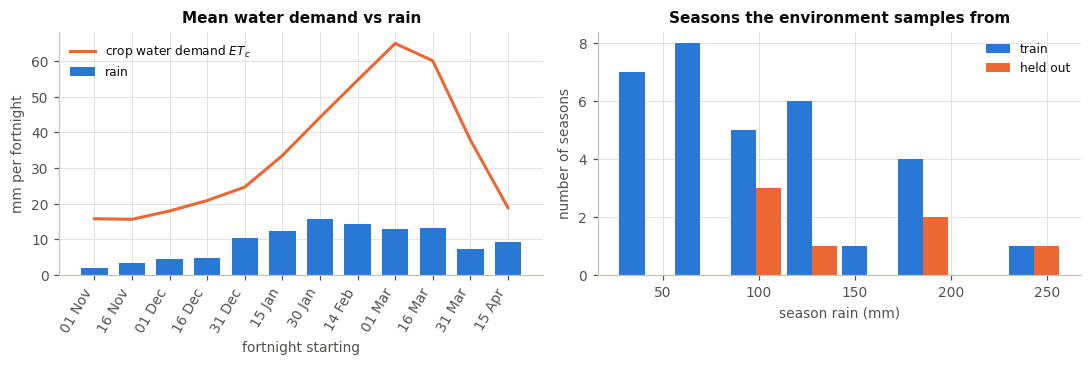

saved results\figures\env_calibration.png
mean season crop water demand: 409 mm, mean rain: 110 mm


In [12]:
env_train = FarmEnv(cfg["env"], split="train")
env_test = FarmEnv(cfg["env"], split="test")
print(f"train seasons ({len(env_train.seasons)}): {env_train.seasons[0]}-{env_train.seasons[-1]}")
print(f"test seasons  ({len(env_test.seasons)}): {env_test.seasons}")
print("yield model   :", {k: round(v, 4) for k, v in env_train.ym.params().items()})
print("unit costs    :", cfg["env"]["costs"])

split = np.where(summary["season"] <= cfg["env"]["train_end"], "train", "test")
display(summary.assign(split=split).merge(prices[["season", "price_index"]], on="season", how="left")
        .groupby("split")[["rain_mm", "et0_mm", "t_mean", "late_t_max", "price_index"]].agg(["mean", "std"]).round(2))

kc = np.array(env_train.dyn["kc"])
etc = seasons.assign(etc=seasons["et0_mm"] * kc[seasons["step"]])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
g = etc.groupby("step")
ax.plot(fx, g["etc"].mean(), color=COLORS[1], label="crop water demand $ET_c$")
ax.bar(fx, g["rain_mm"].mean(), color=COLORS[0], width=0.7, label="rain")
ax.set_xticks(fx); ax.set_xticklabels(labels, rotation=60, ha="right")
ax.set(xlabel="fortnight starting", ylabel="mm per fortnight", title="Mean water demand vs rain")
ax.legend(loc="upper left")
ax = axes[1]
tot = etc.groupby("season")[["etc", "rain_mm"]].sum()
ax.hist([tot.loc[train_years, "rain_mm"], tot.loc[test_years, "rain_mm"]], bins=8, color=[COLORS[0], COLORS[1]],
        label=["train", "held out"], rwidth=0.9)
ax.set(xlabel="season rain (mm)", ylabel="number of seasons", title="Seasons the environment samples from")
ax.legend()
fig.tight_layout()
show(fig, "env_calibration")
print(f"mean season crop water demand: {tot['etc'].mean():.0f} mm, mean rain: {tot['rain_mm'].mean():.0f} mm")

## 5. Sanity checks

Before training we check that the environment behaves: observations stay inside the
declared space, episodes last exactly $T$ steps, a random policy produces a wide but finite
reward distribution, and the extreme policies are ordered as agronomy says they should be
(no inputs and maximum inputs both do badly; the recommended schedule sits near observed
farm outcomes).

observation: {'stage': 1.0, 'soil_moisture': 0.88, 'soil_n': 0.78, 'pest': 0.0, 'cum_rain': 0.27, 'cum_n': 1.3, 'cum_water': 1.16, 'price_index': 0.97, 'last_rain': 0.11, 'last_et0': 0.98, 'et_ratio': 1.0}


,profit,profit_std,reward,yield,n_total,irrigation_total,pesticide_total
policy,,,,,,,
no_input,-6558.7,9509.8,-6558.7,9.4,0.0,0.0,0.0
recommended,76056.8,7537.1,74456.8,45.0,120.0,300.0,1.0
always_max,-66608.0,0.0,-73569.5,0.0,480.0,900.0,24.0


random policy over 800 episodes: reward mean 36,152, std 28,464, min -57,761, max 82,352 INR/ha


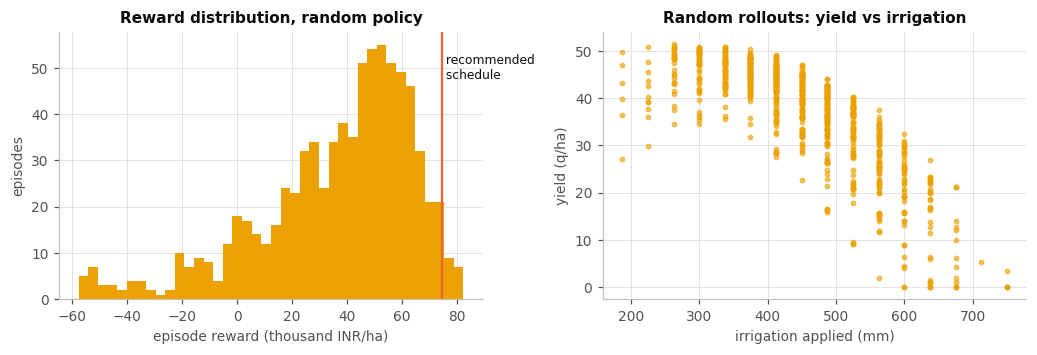

saved results\figures\sanity_random_policy.png


In [13]:
random_eps = evaluate(env_train, {"random": BASELINES["random"]}, seeds_per_season=25, seed0=SEED)
obs, _ = env_train.reset(seed=SEED)
assert env_train.observation_space.contains(obs), "observation outside the declared space"
steps, done = 0, False
while not done:
    obs, r, done, _, info = env_train.step(BASELINES["random"](obs, env_train))
    assert env_train.observation_space.contains(obs) and np.isfinite(r)
    steps += 1
assert steps == env_train.T
print("observation:", dict(zip(OBS_NAMES, np.round(obs, 2))))

always_max = lambda o, e: np.array([2, 2, 2])
checks = summarise(evaluate(env_train, {"no_input": BASELINES["no_input"], "recommended": BASELINES["recommended"],
                                        "always_max": always_max}, seeds_per_season=5, seed0=SEED))
display(checks.round(1))
print(f"random policy over {len(random_eps)} episodes: reward mean {random_eps['reward'].mean():,.0f}, "
      f"std {random_eps['reward'].std():,.0f}, min {random_eps['reward'].min():,.0f}, max {random_eps['reward'].max():,.0f} INR/ha")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3))
axes[0].hist(random_eps["reward"] / 1000, bins=40, color=COLORS[3])
axes[0].axvline(checks.loc["recommended", "reward"] / 1000, color=COLORS[1], lw=1.5)
axes[0].text(checks.loc["recommended", "reward"] / 1000, axes[0].get_ylim()[1] * 0.92, " recommended\n schedule", fontsize=8, va="top")
axes[0].set(xlabel="episode reward (thousand INR/ha)", ylabel="episodes", title="Reward distribution, random policy")
axes[1].scatter(random_eps["irrigation_total"], random_eps["yield"], s=8, color=COLORS[3], alpha=0.6)
axes[1].set(xlabel="irrigation applied (mm)", ylabel="yield (q/ha)", title="Random rollouts: yield vs irrigation")
fig.tight_layout()
show(fig, "sanity_random_policy")

## 6. Training PPO

The agent is our own implementation (`src/farmrl/agents/ppo.py`): a shared two-layer tanh
network with three categorical heads (one per input) and a value head, the clipped surrogate
objective, generalised advantage estimation, minibatch Adam updates and gradient clipping.
It is trained only on the training seasons; seeds are fixed, so the run is repeatable.

In [14]:
set_seed(SEED)
env_train = FarmEnv(cfg["env"], split="train")
env_train.reset(seed=SEED)
agent = PPO(env_train, cfg["train"])
print("hyperparameters:", cfg["train"])
history = agent.learn(cfg["train"]["total_timesteps"])
to_kinr = env_train.reward_scale / 1000
history = [h * to_kinr for h in history]
(ROOT / "results/models").mkdir(parents=True, exist_ok=True)
agent.save(ROOT / "results/models/ppo_latest.pt")
json.dump(history, open(ROOT / "results/train_history.json", "w"))
print(f"{len(history)} iterations of {cfg['train']['n_steps']} steps; "
      f"mean episode return: first {history[0]:.1f}, last {history[-1]:.1f} thousand INR/ha")

hyperparameters: {'total_timesteps': 200000, 'lr': 0.0003, 'gamma': 0.99, 'gae_lambda': 0.95, 'clip_eps': 0.2, 'n_steps': 2048, 'batch_size': 64, 'epochs': 10, 'hidden': 64, 'ent_coef': 0.01, 'vf_coef': 0.5}


97 iterations of 2048 steps; mean episode return: first 35.6, last 85.4 thousand INR/ha


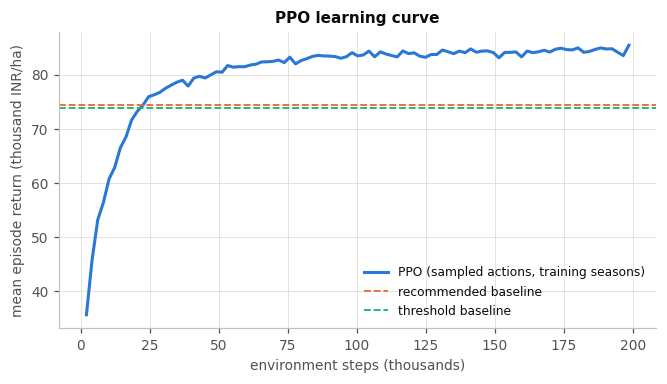

saved results\figures\training_curve.png


In [15]:
ref = summarise(evaluate(env_train, {k: BASELINES[k] for k in ("recommended", "threshold")}, seeds_per_season=5, seed0=SEED))
fig, ax = plt.subplots(figsize=(7, 3.5))
steps_axis = (np.arange(len(history)) + 1) * cfg["train"]["n_steps"] / 1000
ax.plot(steps_axis, history, color=COLORS[0], label="PPO (sampled actions, training seasons)")
for name in ref.index:
    ax.axhline(ref.loc[name, "reward"] / 1000, color=POLICY_COLORS[name], lw=1.2, ls="--", label=f"{name} baseline")
ax.set(xlabel="environment steps (thousands)", ylabel="mean episode return (thousand INR/ha)", title="PPO learning curve")
ax.legend(loc="lower right")
show(fig, "training_curve")

## 7. Evaluation on held-out seasons

All policies are run on the held-out seasons (2017 onwards). Pest growth is random, so
each season is replayed with 30 seeds, shared across policies. PPO acts greedily (argmax).
*Profit* is net of input and fixed costs but excludes the environmental penalty terms;
*reward* includes them.

In [16]:
policies = {"ppo": lambda o, e: agent.predict(o), **{k: BASELINES[k] for k in ("threshold", "recommended", "random", "no_input")}}
episodes = evaluate(env_test, policies, seeds_per_season=cfg["eval"]["seeds_per_season"])
table = summarise(episodes)
episodes.to_csv(ROOT / "results/eval_episodes.csv", index=False)
json.dump(table.round(3).to_dict(orient="index"), open(ROOT / "results/eval.json", "w"), indent=2)

pretty = table.rename(columns={"profit": "profit (INR/ha)", "profit_std": "profit std", "reward": "reward (INR/ha)",
                               "yield": "yield (q/ha)", "n_total": "N (kg/ha)", "irrigation_total": "irrigation (mm)",
                               "pesticide_total": "pesticide (dose units)"})
display(pretty.style.format("{:,.0f}").format({"yield (q/ha)": "{:.1f}", "pesticide (dose units)": "{:.1f}"}))
by_season = episodes.pivot_table(index="season", columns="policy", values="profit")[list(policies)]
print("mean profit by held-out season (INR/ha):")
display(by_season.round(0).assign(rain_mm=summary.set_index("season")["rain_mm"]))

,profit (INR/ha),profit std,reward (INR/ha),yield (q/ha),N (kg/ha),irrigation (mm),pesticide (dose units)
policy,,,,,,,
ppo,84456.662592,3521.247745,82728.087026,50.0,173.428571,225.000000,3.7
threshold,74399.874922,3485.523558,72510.351113,47.3,140.000000,235.714286,7.1
recommended,69518.004627,8373.139437,67918.004627,42.3,120.000000,300.000000,1.0
random,31852.588723,32384.322867,28432.526139,32.9,244.476190,436.785714,11.8
no_input,3208.086756,11915.244830,3208.086756,13.4,0.000000,0.000000,0.0


mean profit by held-out season (INR/ha):


policy,ppo,threshold,recommended,random,no_input,rain_mm
season,,,,,,
2017,87082.0,77709.0,78355.0,54106.0,-8116.0,92.76
2018,86601.0,77306.0,71141.0,20924.0,10508.0,179.95
2019,87286.0,75694.0,54385.0,-3267.0,27234.0,257.76
2020,85420.0,75323.0,74942.0,39228.0,-8720.0,98.47
2021,78057.0,67440.0,59859.0,30611.0,6974.0,171.41
2022,80854.0,72430.0,73272.0,39398.0,-3904.0,135.21
2023,85896.0,74898.0,74671.0,41969.0,-1519.0,111.10


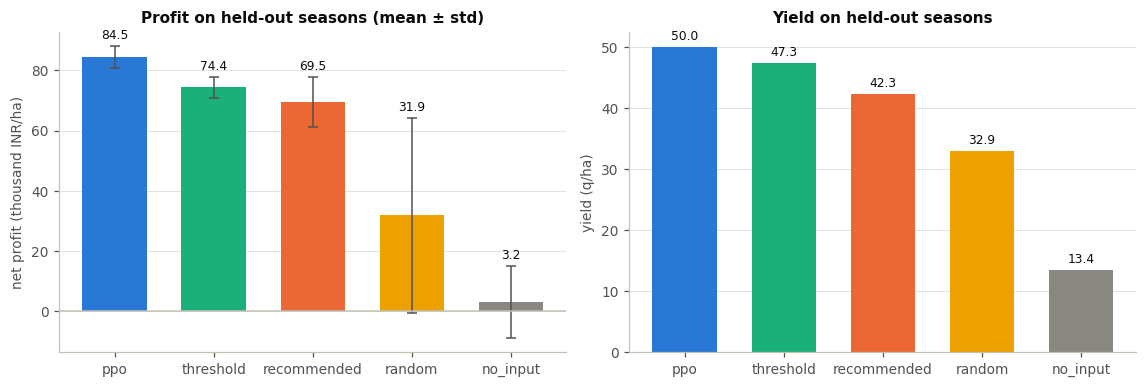

saved results\figures\eval_profit_yield.png


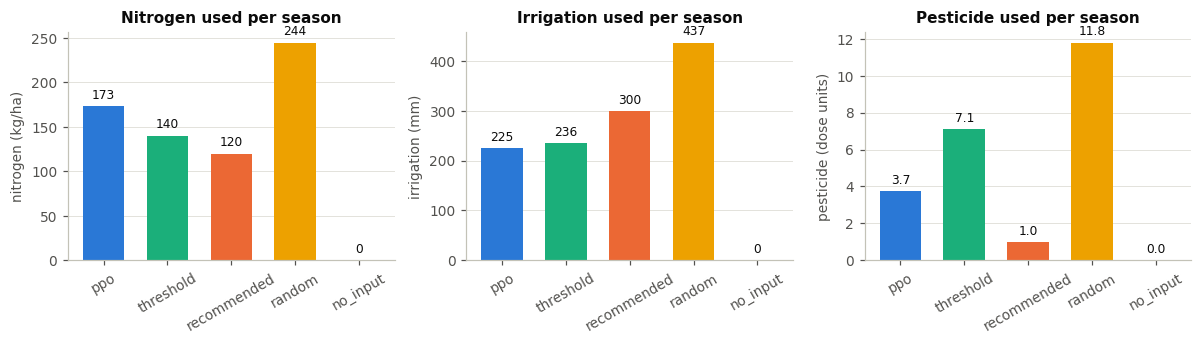

saved results\figures\eval_inputs_used.png


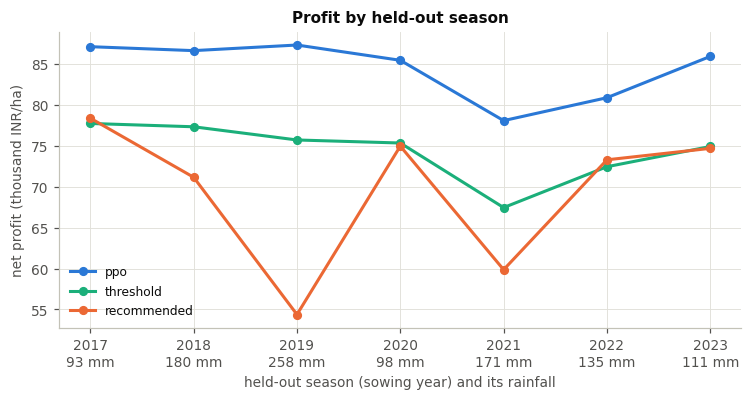

saved results\figures\eval_profit_by_season.png


In [17]:
names = list(policies)
colors = [POLICY_COLORS[n] for n in names]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax = axes[0]
bars = ax.bar(names, table.loc[names, "profit"] / 1000, yerr=table.loc[names, "profit_std"] / 1000, color=colors,
              width=0.65, capsize=3, error_kw={"elinewidth": 1, "ecolor": "#52514e"})
ax.bar_label(bars, labels=[f"{v / 1000:.1f}" for v in table.loc[names, "profit"]], padding=3, fontsize=8)
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set(ylabel="net profit (thousand INR/ha)", title="Profit on held-out seasons (mean ± std)")
ax.grid(axis="x", visible=False)
ax = axes[1]
bars = ax.bar(names, table.loc[names, "yield"], color=colors, width=0.65)
ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8)
ax.set(ylabel="yield (q/ha)", title="Yield on held-out seasons")
ax.grid(axis="x", visible=False)
fig.tight_layout()
show(fig, "eval_profit_yield")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col, ylabel in zip(axes, ["n_total", "irrigation_total", "pesticide_total"],
                           ["nitrogen (kg/ha)", "irrigation (mm)", "pesticide (dose units)"]):
    bars = ax.bar(names, table.loc[names, col], color=colors, width=0.65)
    ax.bar_label(bars, fmt="%.0f" if col != "pesticide_total" else "%.1f", padding=3, fontsize=8)
    ax.set(ylabel=ylabel, title=ylabel.split(" (")[0].capitalize() + " used per season")
    ax.tick_params(axis="x", rotation=30); ax.grid(axis="x", visible=False)
fig.tight_layout()
show(fig, "eval_inputs_used")

fig, ax = plt.subplots(figsize=(8, 3.5))
for n in ["ppo", "threshold", "recommended"]:
    ax.plot(by_season.index, by_season[n] / 1000, marker="o", color=POLICY_COLORS[n], label=n)
ax.set_xticks(by_season.index)
ax.set_xticklabels([f"{s}\n{summary.set_index('season').loc[s, 'rain_mm']:.0f} mm" for s in by_season.index])
ax.set(xlabel="held-out season (sowing year) and its rainfall", ylabel="net profit (thousand INR/ha)", title="Profit by held-out season")
ax.legend()
show(fig, "eval_profit_by_season")

## 8. Policy analysis

What did the agent learn to do? First, its input schedule across a season, next to the
fixed recommended calendar, for the driest and the wettest held-out season. Then its
irrigation choice across *all* seasons as a function of how much rain fell.

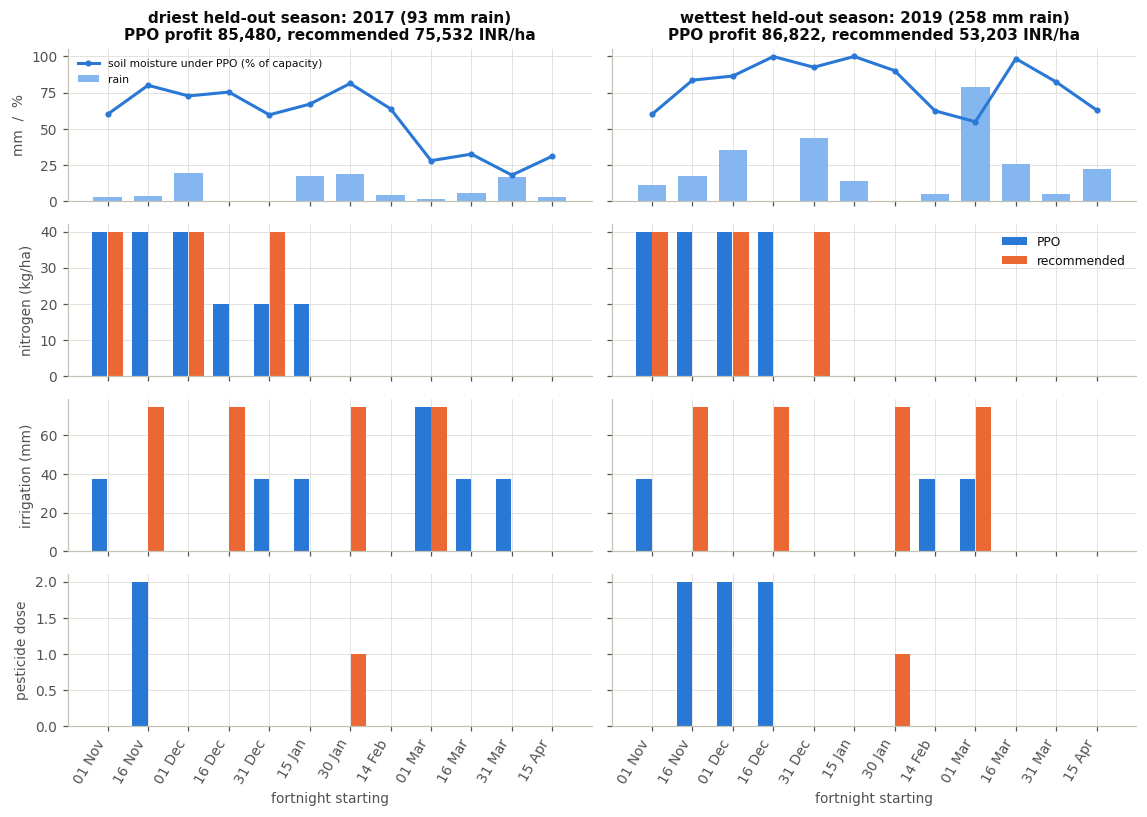

saved results\figures\policy_schedules_dry_vs_wet.png


In [18]:
test_rain = summary.set_index("season").loc[env_test.seasons, "rain_mm"]
dry, wet = int(test_rain.idxmin()), int(test_rain.idxmax())
ppo_policy = policies["ppo"]
fig, axes = plt.subplots(4, 2, figsize=(10.5, 7.5), sharex=True, sharey="row")
for j, (season, tag) in enumerate([(dry, "driest"), (wet, "wettest")]):
    tr_ppo = run_episode(env_test, ppo_policy, season=season, seed=SEED, trace=True)
    tr_rec = run_episode(env_test, BASELINES["recommended"], season=season, seed=SEED, trace=True)
    s_ppo, s_rec = tr_ppo["steps"], tr_rec["steps"]
    xs = s_ppo["step"].to_numpy()
    axes[0, j].bar(xs, s_ppo["rain"], color="#86b6ef", width=0.7, label="rain")
    axes[0, j].plot(xs, s_ppo["soil_moisture"] * 100, color=COLORS[0], marker="o", ms=3, label="soil moisture under PPO (% of capacity)")
    axes[0, j].set_title(f"{tag} held-out season: {season} ({test_rain[season]:.0f} mm rain)\n"
                         f"PPO profit {tr_ppo['profit']:,.0f}, recommended {tr_rec['profit']:,.0f} INR/ha")
    for i, (col, ylabel) in enumerate([("nitrogen", "nitrogen (kg/ha)"), ("irrigation", "irrigation (mm)"), ("pesticide", "pesticide dose")], start=1):
        axes[i, j].bar(xs - 0.2, s_ppo[col], width=0.38, color=POLICY_COLORS["ppo"], label="PPO")
        axes[i, j].bar(xs + 0.2, s_rec[col], width=0.38, color=POLICY_COLORS["recommended"], label="recommended")
        axes[i, 0].set_ylabel(ylabel)
    axes[3, j].set_xticks(xs); axes[3, j].set_xticklabels(labels, rotation=60, ha="right"); axes[3, j].set_xlabel("fortnight starting")
axes[0, 0].set_ylabel("mm  /  %")
axes[0, 0].legend(loc="upper left", fontsize=7); axes[1, 1].legend(loc="upper right")
fig.tight_layout()
show(fig, "policy_schedules_dry_vs_wet")

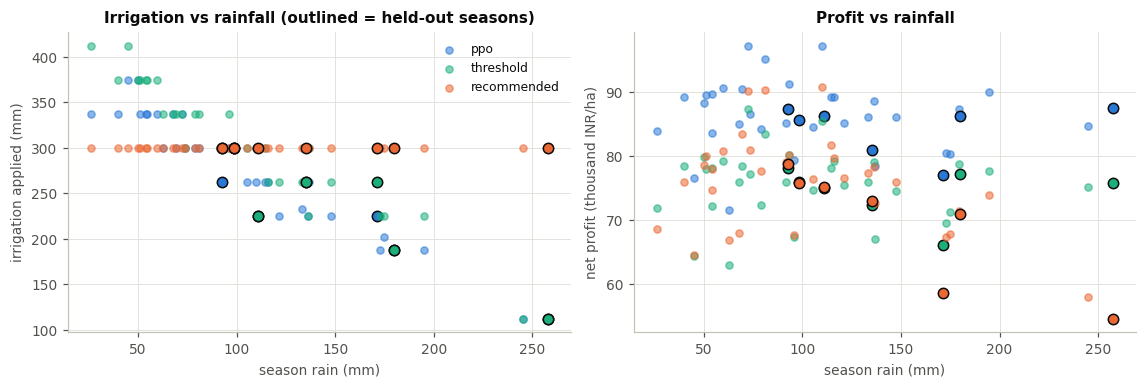

saved results\figures\policy_dry_vs_wet_years.png
PPO behaviour by rainfall tercile (all 39 seasons):


,rain_total,irrigation_total,n_total,pesticide_total,yield,profit
rain_total,,,,,,
dry third,55.9,334.6,174.8,2.1,50.3,86332.9
middle third,100.8,271.2,169.8,2.7,50.2,87697.5
wet third,174.3,200.8,174.5,2.8,49.8,84144.5


change in irrigation per extra mm of season rain: {'ppo': -1.12, 'recommended': 0.0, 'threshold': -1.24}


In [19]:
env_all = FarmEnv(cfg["env"], split="all")
behaviour = evaluate(env_all, {"ppo": ppo_policy, "threshold": BASELINES["threshold"], "recommended": BASELINES["recommended"]},
                     seeds_per_season=5, seed0=SEED)
per_season = behaviour.groupby(["policy", "season"], sort=False)[["irrigation_total", "n_total", "pesticide_total", "rain_total", "profit", "yield"]].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for name in ["ppo", "threshold", "recommended"]:
    d = per_season[per_season["policy"] == name]
    held = d["season"] > cfg["env"]["train_end"]
    axes[0].scatter(d["rain_total"][~held], d["irrigation_total"][~held], s=22, color=POLICY_COLORS[name], alpha=0.55, label=f"{name}")
    axes[0].scatter(d["rain_total"][held], d["irrigation_total"][held], s=46, color=POLICY_COLORS[name], edgecolor="#0b0b0b", lw=1)
    axes[1].scatter(d["rain_total"][~held], d["profit"][~held] / 1000, s=22, color=POLICY_COLORS[name], alpha=0.55, label=name)
    axes[1].scatter(d["rain_total"][held], d["profit"][held] / 1000, s=46, color=POLICY_COLORS[name], edgecolor="#0b0b0b", lw=1)
axes[0].set(xlabel="season rain (mm)", ylabel="irrigation applied (mm)", title="Irrigation vs rainfall (outlined = held-out seasons)")
axes[1].set(xlabel="season rain (mm)", ylabel="net profit (thousand INR/ha)", title="Profit vs rainfall")
axes[0].legend(); fig.tight_layout()
show(fig, "policy_dry_vs_wet_years")

ppo_seasons = per_season[per_season["policy"] == "ppo"].copy()
terciles = pd.qcut(ppo_seasons["rain_total"], 3, labels=["dry third", "middle third", "wet third"])
print("PPO behaviour by rainfall tercile (all 39 seasons):")
display(ppo_seasons.groupby(terciles, observed=True)[["rain_total", "irrigation_total", "n_total", "pesticide_total", "yield", "profit"]].mean().round(1))
slope = {n: np.polyfit(d["rain_total"], d["irrigation_total"], 1)[0] for n, d in per_season.groupby("policy")}
print("change in irrigation per extra mm of season rain:", {k: round(v, 2) for k, v in slope.items()})

## 9. Conclusions and limitations

**What the results show** (held-out seasons 2017–2023, 30 replicates each):

| Policy | Net profit (INR/ha) | Std | Yield (q/ha) | N (kg/ha) | Irrigation (mm) | Pesticide (doses) |
|---|---|---|---|---|---|---|
| PPO (ours) | 84,457 | 3,521 | 50.0 | 173 | 225 | 3.7 |
| Threshold rules | 74,400 | 3,486 | 47.3 | 140 | 236 | 7.1 |
| Recommended calendar | 69,518 | 8,373 | 42.3 | 120 | 300 | 1.0 |
| Random | 31,853 | 32,384 | 32.9 | 244 | 437 | 11.8 |
| No inputs | 3,208 | 11,915 | 13.4 | 0 | 0 | 0 |

* PPO earns about 10,100 INR/ha (14%) more than the threshold rules and about 14,900 INR/ha
  (21%) more than the fixed recommended calendar, and it is ahead in every one of the seven
  held-out seasons. The learning curve passes both baselines after roughly 25,000 steps
  and flattens near 85,000 INR/ha.
* It does this with **25% less irrigation water** than the calendar (225 vs 300 mm), but
  with more nitrogen (173 vs 120 kg/ha) and more pesticide (3.7 vs 1 dose).
* The gain comes mostly from adapting to the weather. Across all 39 seasons the agent
  applies about 335 mm in the driest third of years and about 200 mm in the wettest third,
  roughly 1.1 mm less irrigation for every extra mm of rain. The calendar applies 300 mm
  regardless, which is why it loses most in wet years (2019: 54,000 vs PPO's 87,000 INR/ha).
* Its profit is also steadier across seasons than the calendar's (std 3,500 vs 8,400).
* The schedules are agronomically recognisable: nitrogen is front-loaded into the first
  ten weeks and stops by late January, and irrigation is given in half-doses that track
  soil moisture rather than as four fixed full irrigations.

**Limitations: read the numbers above as results in a simulator, not field advice.**

1. **The yield data are from Haryana, not Punjab.** The ICRISAT files available cover seven
   Haryana districts for 2008–2017. Costs (CACP) and weather (Ludhiana) are Punjab.
2. **The yield fit is weak (R² = 0.24, 70 points).** District nitrogen use never falls below
   89 kg/ha, so the response at low doses is an extrapolation, and the nitrogen figure is
   an all-crop annual average, not the wheat dose. Irrigation depth is not observed at all;
   we assumed 300 mm for every record.
3. **The pesticide response is not fitted.** The FAO/Kaggle table could not be downloaded
   (no Kaggle token), so `pest_loss = 0.35` and the whole pest sub-model are assumptions.
   The agent's habit of spraying heavily in November–December exploits that sub-model
   (early kills compound) and should not be read as a recommendation.
4. **Prices are the MSP, not mandi prices** (Agmarknet was unreachable), so price risk is
   close to absent; the agent never had to trade off against a volatile market.
5. **Several dynamics are assumed rather than calibrated**: soil water capacity, crop
   coefficients, nitrogen timing efficiency and leaching, and all three penalty weights.
   Unit costs for irrigation and pesticide divide CACP per-hectare spending by an assumed
   number of applications; the nitrogen price is the notified urea price, not a CACP figure.
6. **The baselines were not tuned to the simulator**, whereas PPO was trained in it. Part of
   PPO's margin is this home advantage: its extra nitrogen pays off because the fitted
   curve still rises slightly above 120 kg/ha.
7. **Seven held-out seasons** is a small test set, and they are wetter than the training
   years (mean 150 vs 102 mm), which favours any policy that adapts irrigation.
8. Only weather-, price- and pest-driven uncertainty is modelled: no hail, lodging, heat
   stress at grain filling, or sowing-date choice, which the residuals suggest matter.

**Next steps.** Obtain the Punjab ICRISAT files (with irrigated area), the FAO pesticide
table and Agmarknet prices; refit; add late-season heat to the yield model; and compare
against a baseline tuned on the training seasons.